# Model 04 · Which app will I open next?
8-class classifier on lag features. No LSTM: three lags, one-hot encoded, are enough for a phone habit.

In [1]:
import sys
sys.path.insert(0, "../_shared")
try:
    import kit
except ImportError:
    from google.colab import files; files.upload(); import kit
from kit import *

## 1 · Dataset generator
A second-order Markov process with context effects: time of day, notifications, activity, battery,
and an A→B→A→B ping-pong pattern (the one thing a plain logistic model cannot express).

In [2]:
APPS = ["Instagram", "WhatsApp", "YouTube", "Chrome", "Gmail", "Spotify", "Maps", "Notes"]
ACTS = ["studying", "working", "relaxing", "commuting", "eating", "bored"]
IDX = {a: i for i, a in enumerate(APPS)}
ACT_B = {"studying": {"Notes": .9, "Chrome": .7, "YouTube": .3}, "working": {"Gmail": .9, "Chrome": .6, "WhatsApp": .2},
         "relaxing": {"Instagram": .7, "YouTube": .8, "Spotify": .4}, "commuting": {"Maps": 1.3, "Spotify": .8, "WhatsApp": .3},
         "eating": {"Instagram": .4, "WhatsApp": .4, "YouTube": .5}, "bored": {"Instagram": 1.0, "YouTube": .6}}

def transitions():
    K = len(APPS); r = np.random.default_rng(7); B = r.normal(0, .35, (K, K))
    for a, b, w in [("Instagram", "WhatsApp", 1.4), ("WhatsApp", "Instagram", 1.5), ("YouTube", "Instagram", 1.1), ("Instagram", "YouTube", .9),
                    ("Chrome", "Gmail", 1.0), ("Gmail", "Chrome", 1.0), ("Chrome", "YouTube", .7), ("Spotify", "Instagram", .6),
                    ("Maps", "WhatsApp", .8), ("Notes", "Chrome", .9), ("Chrome", "Notes", .6), ("WhatsApp", "Gmail", .4)]:
        B[IDX[a], IDX[b]] += w
    np.fill_diagonal(B, -3.0)
    return B, np.random.default_rng(8).normal(0, .25, (K, K)), np.random.default_rng(9).normal(0, .15, (K, K))

def generate(n=20000, seed=SEED):
    r = np.random.default_rng(seed); K = len(APPS); B, B2, B3 = transitions()
    prior = np.array([.22, .18, .16, .14, .08, .08, .06, .08])
    p1, p2, p3 = (r.choice(K, n, p=prior) for _ in range(3))
    d = pd.DataFrame({"prev1": np.array(APPS)[p1], "prev2": np.array(APPS)[p2], "prev3": np.array(APPS)[p3],
        "hour": np.round(r.uniform(0, 24, n), 1), "session_min": np.round(np.clip(np.exp(r.normal(2.8, 1, n)), 1, 240)),
        "battery": np.round(np.clip(r.beta(2.2, 1.6, n) * 100, 1, 100)), "notifications": np.clip(r.poisson(6, n), 0, 40),
        "weekend": r.choice([0, 1], n, p=[5 / 7, 2 / 7]), "opens_today": np.clip(r.poisson(35, n), 0, 150),
        "activity": r.choice(ACTS, n, p=[.14, .2, .24, .1, .12, .2])})
    L = B[p1] + B2[p2] + B3[p3]
    night = ((d.hour >= 21) | (d.hour < 2)).to_numpy(float); work = ((d.hour >= 9) & (d.hour < 18) & (d.weekend == 0)).to_numpy(float)
    L[:, [0, 2]] += 0.9 * night[:, None]; L[:, 4] += 0.8 * work
    L[:, 5] += 0.5 * (((d.hour >= 7) & (d.hour < 10)) | ((d.hour >= 17) & (d.hour < 20))).to_numpy(float)
    L[:, [0, 1]] += 0.05 * d.notifications.to_numpy()[:, None]; L[:, 0] += 0.012 * d.opens_today.to_numpy()
    L[:, [2, 6]] -= 0.6 * (d.battery < 20).to_numpy(float)[:, None]
    for act, boosts in ACT_B.items():
        m = (d.activity == act).to_numpy()
        for app, w in boosts.items(): L[m, IDX[app]] += w
    pp = (p1 == p3) & (p1 != p2); L[np.where(pp)[0], p2[pp]] += 1.6
    P = softmax(1.5 * L); nxt = sample_categorical(P, r)
    d["next_app"] = np.array(APPS)[nxt]; d["oracle_hit"] = (P.argmax(1) == nxt).astype(int)
    return d

In [3]:
df = generate(20000); df.drop(columns="oracle_hit").to_csv("dataset.csv", index=False)
print(df.shape, "| oracle top-1 accuracy:", round(df.oracle_hit.mean(), 3)); df.next_app.value_counts(normalize=True).round(3)

(20000, 12) | oracle top-1 accuracy: 0.575


next_app
Instagram    0.361
WhatsApp     0.198
Gmail        0.103
YouTube      0.091
Notes        0.079
Chrome       0.066
Spotify      0.064
Maps         0.037
Name: proportion, dtype: float64

## 2 · Cleaning + EDA

In [4]:
print("nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
df.drop(columns="oracle_hit").head()

nulls: 0 | duplicates: 0


,prev1,prev2,prev3,hour,session_min,battery,notifications,weekend,opens_today,activity,next_app
0,Gmail,Gmail,WhatsApp,19.9,23.0,18.0,4,0,36,bored,Notes
1,YouTube,Notes,Instagram,17.6,15.0,88.0,6,0,36,commuting,Instagram
2,Spotify,Instagram,Instagram,20.8,19.0,40.0,6,0,36,relaxing,Instagram
3,Chrome,WhatsApp,Instagram,22.7,12.0,24.0,7,0,44,working,Instagram
4,Instagram,Chrome,Notes,13.5,7.0,85.0,4,1,54,bored,Instagram


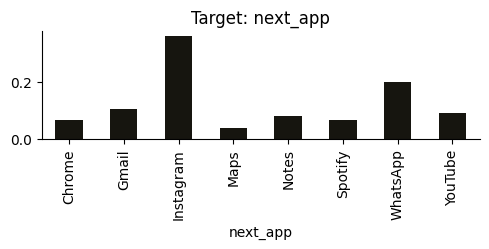

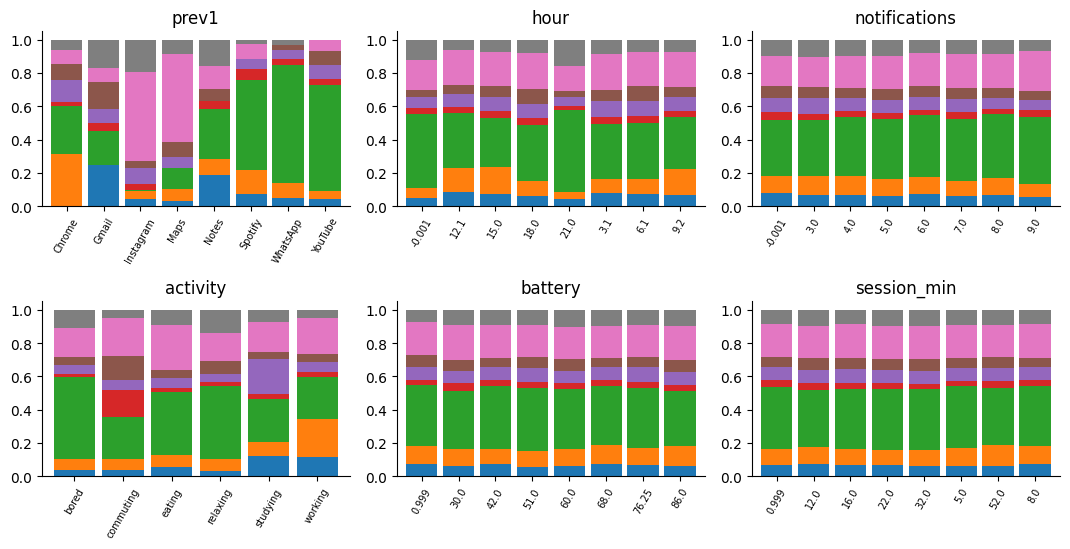

In [5]:
INPUTS = [Cat("prev1", APPS), Cat("prev2", APPS), Cat("prev3", APPS), Num("hour", 0, 24, "cyc"), Num("session_min", 0, 240), Num("battery", 0, 100),
          Num("notifications", 0, 40), Num("weekend", 0, 1), Num("opens_today", 0, 150), Cat("activity", ACTS)]
RAW = [s["name"] for s in INPUTS]; eda(df, "next_app", ["prev1", "hour", "notifications", "activity", "battery", "session_min"], "multiclass", 3)

## 3 · Features, split, train

In [6]:
fz = Featurizer(INPUTS); tr, va, te = split3(df, "next_app")
Xtr, Xva, Xte = fz.transform(tr), fz.transform(va), fz.transform(te)
ytr, yva, yte = (x.next_app.map(IDX).to_numpy() for x in (tr, va, te))
best, best_name, table = train_classifier(Xtr, ytr, Xva, yva, depth=10, leaf=40, trees=40)
print("selected:", best_name); table.round(4)

selected: Logistic Regression


,model,val_log_loss,val_accuracy
0,Logistic Regression,1.2918,0.5573
1,Random Forest,1.3710,0.5337


## 4 · Test evaluation vs baselines

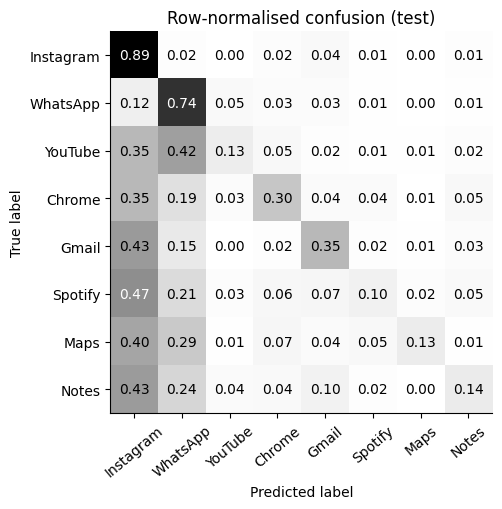

{'accuracy': 0.556,
 'macro_f1': 0.3569,
 'log_loss': 1.2777,
 'top3_accuracy': 0.835,
 'markov_baseline_accuracy': 0.5217,
 'oracle_accuracy': 0.5737}

In [7]:
m = report_multiclass(best, Xte, yte, APPS)
bigram = tr.groupby("prev1").next_app.agg(lambda s: s.value_counts().index[0])
m["markov_baseline_accuracy"] = round(float((te.prev1.map(bigram) == te.next_app).mean()), 4)
m["oracle_accuracy"] = round(float(te.oracle_hit.mean()), 4); m

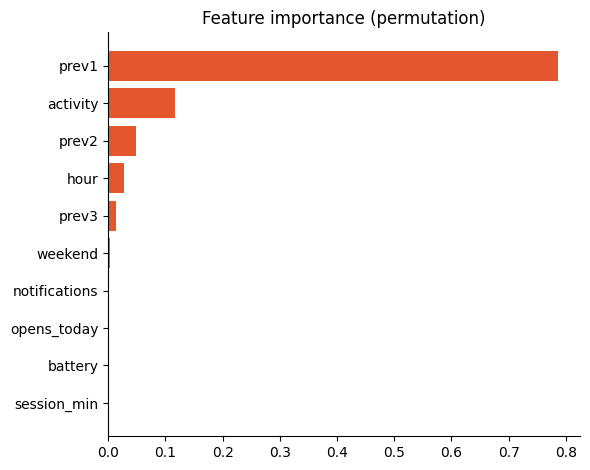

{'prev1': 0.7855,
 'activity': 0.117,
 'prev2': 0.0492,
 'hour': 0.0276,
 'prev3': 0.014,
 'weekend': 0.0031,
 'notifications': 0.0018,
 'opens_today': 0.0011,
 'battery': 0.0005,
 'session_min': 0.0002}

In [8]:
imp = group_importance(best.predict_proba, Xte, yte, fz.groups, lambda y, p: log_loss(y, p, labels=list(range(len(APPS)))))
plot_importance(imp); imp

In [9]:
ex = pd.DataFrame([dict(prev1="Instagram", prev2="WhatsApp", prev3="Instagram", hour=23.5, session_min=40, battery=35, notifications=12, weekend=0, opens_today=60, activity="bored")])
p = best.predict_proba(fz.transform(ex))[0]; sorted(zip(APPS, p.round(3)), key=lambda t: -t[1])[:3]

[('WhatsApp', np.float64(0.693)),
 ('YouTube', np.float64(0.189)),
 ('Notes', np.float64(0.031))]

## 5 · Export + verify

In [10]:
heads = {"next": export_head(best, labels=APPS)}
meta = make_metadata("v1.0", SEED, len(df), {"train": len(tr), "val": len(va), "test": len(te)},
    {"next": {"algorithm": best_name, "task": "multiclass", "metrics": m, "candidates": table.round(4).to_dict("records")}}, imp,
    ["Synthetic habits. Your actual scrolling pattern is more chaotic than any Markov chain.", "Top-1 accuracy is capped by randomness in the generator; see oracle_accuracy."], "generate() in this notebook")
write_artifacts("model", "next-app", "Which app will I open next?", fz, tr, heads, {"next": best}, meta, te[RAW])

wrote model (69 KB total) | export error vs sklearn: {'next': 1.3046277391737249e-09}


{'next': 1.3046277391737249e-09}